# Improve the microscope fit with new lens settings

This continues the [MAGICAL calibration notebook](projector_calibration_pipeline.ipynb). We keep the specimen feature visible and use the same image → measurement → unknown-microscope fit pipeline.

**Result:** the final experiment recovers every one of the 19 parameters within **0.11%** in its first run. Two fully independent noise repeats give maximum errors of **0.10%** and **0.22%**. A frozen fitted model predicts **72 fresh images** at new settings with **0.95 noise-unit error**. A two-stage fit reaches the same solution from **all 20 tested starting models**.

The successful settings include substantial lens changes, not just small wobbles. The result is a synthetic demonstration under our finite-solenoid, linear-control and known-intensity-template assumptions. It does not establish the usable current range or model accuracy of a real microscope.

In [1]:
from pathlib import Path
import sys
import os
import json
import numpy as np

os.environ.setdefault("XLA_PYTHON_CLIENT_PREALLOCATE", "false")
import jax
jax.config.update("jax_enable_x64", True)

project_folder = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src/temgym_core").is_dir())
sys.path[:0] = [str(project_folder / "src"), str(project_folder / "examples/microscope_models")]
from projector_adaptive_experiments import (
    load_calibration_checkpoint, design_lens_settings, run_calibration_round,
    check_new_predictions, repeat_noise_protocol, run_recovery_checks,
)
from projector_adaptive_report import (
    show_round_results, show_final_parameters, show_selected_controls, show_recovery_checks,
)
from projector_notebook_helpers import show_images

%matplotlib inline

results_folder = project_folder / "examples/generated/adaptive_projector_fit"
reuse_completed = True        # False regenerates images and refits; this can take several minutes.


## 1. Start from the existing fit

**Supply:** the completed earlier calibration.

**Get back:** the current named microscope model, all measured image/tilt/beam-shift data, and the original fixed priors. The true microscope is read only when generating synthetic images or scoring the final parameters.

The objective was fixed in the earlier experiment. IL1–PL1 were changed one at a time. Tilt and beam-shift measurements were concentrated at IL1-wobble settings.

In [2]:
baseline = load_calibration_checkpoint(
    directory=project_folder / "examples/generated/simple_magical_fit",
)


## 2. Choose useful combinations and test their predictions

We screen two-lens grids with both same-direction and opposite-direction changes, plus mixed changes of all four projector lenses. A sensitivity calculation chooses settings expected to constrain the current weak parameter combinations. This ranking uses the current fitted model and estimated measurement noise; it never uses the generating parameters.

Each chosen setting supplies **nine independent images**: one ordinary image, four images with ±3 mrad tilts, and four with ±10 nm beam shifts. The specimen, 100 nm illumination radius, exposure rule and drift model stay the same.

**Supply:** the current calibration, candidate settings and the number of settings to measure.

**Get back:** a new fitted model and the accumulated measurements. The helper saves predictions before generating the new images, measures those images, then refits with unchanged priors. It tries the previous fit and the original literal guess, and rejects fits whose errors are too large even if the optimizer reports convergence.

In [3]:
candidates = design_lens_settings(
    calibration=baseline,
    wider_compensation=False,
    output_path=results_folder / "candidate_settings.npz",
    random_seed=772,
    reuse_completed=reuse_completed,
)

projector_round = run_calibration_round(
    previous=baseline,
    candidates=candidates,
    settings_to_measure=8,
    vary_objective=False,
    wider_compensation=False,
    output_directory=results_folder / "projector_combinations",
    random_seed=1901,
    reuse_completed=reuse_completed,
)


## 3. Vary the objective and compensate the projector lenses

The paper uses two-dimensional lens sweeps and separately changes the objective to calibrate its position and strength ([pages 3–5](../lens_inversion/paper/2607.29411v1.pdf#page=3)). That suggests a control we had not yet used.

Our numerical checks found one very weak geometry direction with the objective fixed. Small objective changes strengthen that direction. We adjust IL1 and IL2 in the **current fitted model** to keep the predicted image visible while the objective changes. The true microscope may disagree; the new images test that prediction.

In [4]:
objective_round = run_calibration_round(
    previous=projector_round,
    candidates=candidates,
    settings_to_measure=8,
    vary_objective=True,
    wider_compensation=False,
    output_directory=results_folder / "objective_combinations",
    random_seed=2101,
    reuse_completed=reuse_completed,
)


## 4. Explore a wider range while retaining the feature

The next design changes IL3 and PL1 more strongly and again adjusts IL1/IL2 to keep useful magnification and blur. It retains predicted effective magnifications between 20,000× and 53,000× and blur below three pixels.

These are exploratory optical configurations: some IL1/IL2 controls reach **three to four times** their reference values. The model assumes its linear excitation law remains valid there. Real hardware limits, hysteresis and saturation have not been tested.

For the final fit, first estimate the **16 optical parameters** from calibrated beam and tilt displacements alone. These signed responses do not require known illumination curvature, angular spread or specimen rotation. Then fit **all 19 parameters jointly** with the ordinary image measurements and the original priors. Each measurement appears once in the final objective. This fitting order avoids the barriers that a poor initial model encounters in log-scale and image-angle measurements.

In [5]:
wide_candidates = design_lens_settings(
    calibration=objective_round,
    wider_compensation=True,
    output_path=results_folder / "wide_candidate_settings.npz",
    random_seed=2917,
    reuse_completed=reuse_completed,
)

wide_round = run_calibration_round(
    previous=objective_round,
    candidates=wide_candidates,
    settings_to_measure=12,
    vary_objective=True,
    wider_compensation=True,
    output_directory=results_folder / "wider_combinations",
    random_seed=3101,
    initialize_from_displacements=True,
    reuse_completed=reuse_completed,
)

show_selected_controls(
    calibration=wide_round,
    reference_controls=baseline.source_experiment.lens_controls[0],
)


Setting,Objective,IL1,IL2,IL3,PL1
1,+0.000%,+239.413%,-9.596%,+40.000%,+50.000%
2,+0.000%,+167.512%,+5.858%,+40.000%,-50.000%
3,+0.000%,+237.676%,-40.260%,-35.000%,+50.000%
4,+0.200%,-7.828%,+2.591%,+40.000%,+50.000%
5,-0.050%,-7.868%,+198.294%,+0.000%,-50.000%
6,+0.200%,-26.805%,+19.637%,+40.000%,+50.000%
7,+0.000%,+133.657%,+7.518%,+20.000%,+50.000%
8,+0.200%,-25.615%,+145.497%,-35.000%,-50.000%
9,+0.100%,-28.257%,+293.247%,+40.000%,-50.000%
10,+0.200%,-27.883%,-30.369%,+20.000%,+50.000%


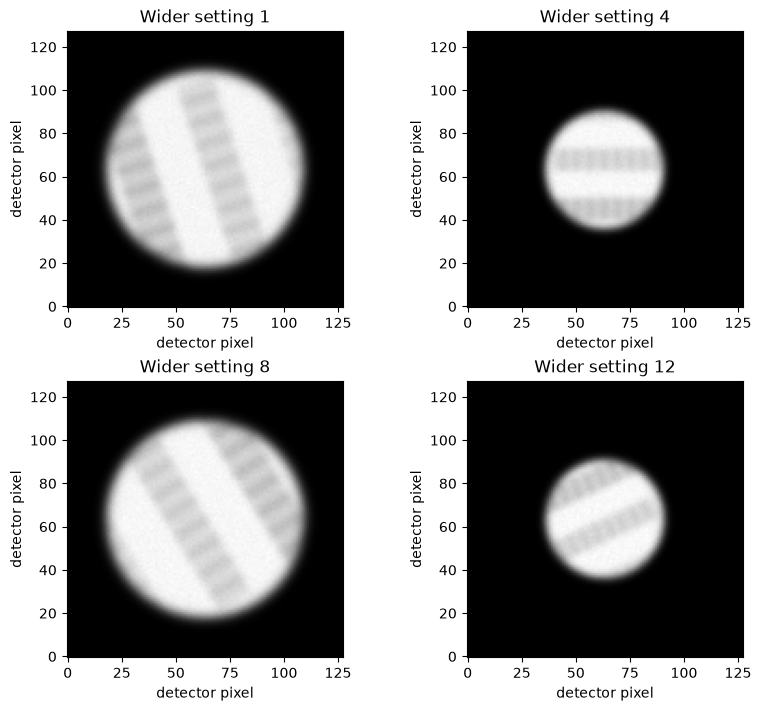

In [6]:
new_images = np.load(wide_round.output_directory / "images.npz")
show_images(
    images=new_images["images"],
    image_labels=[f"Wider setting {i+1}" for i in range(len(new_images["images"]))],
    indices=[0, 3, 7, 11],
)


## 5. Check all parameters and the feedback loop

Each “before” error below compares a frozen model with images it had not yet seen. The “after” error uses those measurements in a refit. An error near one means agreement at approximately the measured noise level.

There are **334 images** in the final calibration. The largest parameter error across the 19 named physical parameters falls from 24.2% to 0.11%. The detector-position error falls from 10.29 mm to about 0.21 mm. Parameter errors are recovery results for these noise realizations, not uncertainty intervals.

In [7]:
rounds = [projector_round, objective_round, wide_round]
show_round_results(baseline=baseline, calibration_rounds=rounds)
final_parameter_errors = show_final_parameters(calibration=wide_round)


Round,Images used in fit,New-data error before fit / noise,After refit / noise,Largest parameter error
Starting calibration,82,—,—,24.168%
Mixed projector settings,154,15.38,0.93,1.649%
Also vary the objective,226,9.38,0.88,2.039%
Wider compensated settings,334,5.13,0.87,0.108%


Parameter,Truth,Fit,Relative error
Objective: Position (mm),2.3,2.2998,-0.0087%
IL1: Position (mm),213.524,213.48,-0.0207%
IL2: Position (mm),290.48,290.406,-0.0256%
IL3: Position (mm),352.98,352.876,-0.0294%
PL1: Position (mm),407.983,407.851,-0.0326%
Objective: Length (mm),0.4,0.399999,-0.0002%
IL1: Length (mm),5,4.99827,-0.0345%
IL2: Length (mm),5,4.99783,-0.0434%
IL3: Length (mm),5,4.99722,-0.0556%
PL1: Length (mm),1,0.999534,-0.0466%


## 6. Predict fresh images without another refit

Choose eight further informative settings outside the fitted data. Save the predictions, acquire 72 independent images, and compare. This check leaves the fitted model unchanged.

In [8]:
already_used = json.loads((wide_round.output_directory / "selection.json").read_text())["indices"]
fresh_prediction_check = check_new_predictions(
    calibration=wide_round,
    candidates=wide_candidates,
    settings_to_measure=8,
    excluded_indices=already_used,
    output_directory=results_folder / "fresh_predictions",
    random_seed=4101,
    reuse_completed=reuse_completed,
)
print(fresh_prediction_check)


{'prediction_rms': 0.9485080622223376, 'image_count': 72, 'measurement_count': 88, 'refitted': False, 'maximum_absolute_residual': 2.7684225297490723}


## 7. Repeat the noise and inspect the remaining uncertainty

Regenerate **all 334 images** twice using independent noise. Keep the same settings, doses and priors, then refit from the original guess and the previous fitted model. No noisy measurements from the first run are reused.

The additional checks remove soft priors, scan detector position while refitting the other 18 parameters, and compare two fitting orders from the same 20 dispersed starting models:

- Direct joint fitting reaches the good solution from **1 of 20** starts.
- Fitting the calibrated displacements first, then all data, reaches the same good solution from **20 of 20** starts.

Using only the calibrated displacements also recovers all **16 optical parameters within 0.39%**, without using a common illumination curvature or angular spread. The full image model improves precision and estimates the remaining three parameters.

These tests support a repeatable calibration within the stated model and bounds. A finite set of starting guesses does not prove global uniqueness over every possible microscope.

Check,Result
"Fresh images, without refitting",72 images; error 0.949 noise units
Independent noise repeat 1,All 19 errors below 0.103%
Independent noise repeat 2,All 19 errors below 0.215%
Remove soft priors,Detector changes by -0.0063 mm
Use calibrated displacements alone,All 16 optical errors below 0.387%; no common illumination parameters needed
Direct fits from 20 dispersed starts,1/20 reached the good solution; others have much larger errors or did not converge
"Fit calibrated displacements first, then all data",20/20 starts reached the same good solution


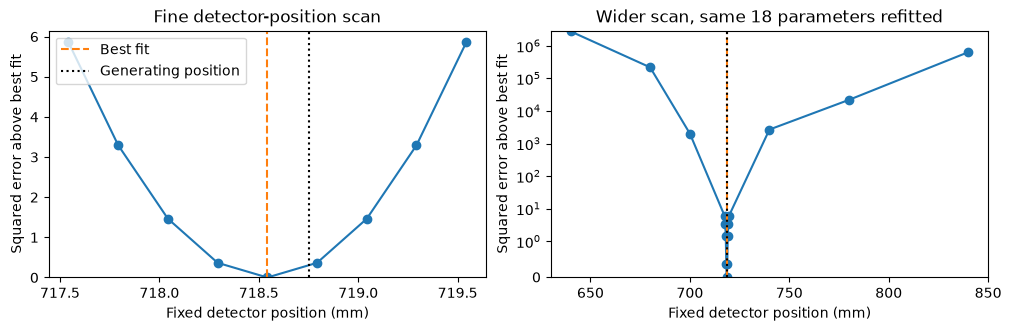

Data,Smallest sensitivity value
Starting calibration,0.000348642
Mixed projectors,0.000728256
Also objective,2.75693
Wider settings,46.8951


Sensitivity values use the same parameter units and measured noise. The smallest value measures the weakest local parameter combination; it is not a global uniqueness proof.


[['Fresh images, without refitting', '72 images; error 0.949 noise units'],
 ['Independent noise repeat 1', 'All 19 errors below 0.103%'],
 ['Independent noise repeat 2', 'All 19 errors below 0.215%'],
 ['Remove soft priors', 'Detector changes by -0.0063 mm'],
 ['Use calibrated displacements alone',
  'All 16 optical errors below 0.387%; no common illumination parameters needed'],
 ['Direct fits from 20 dispersed starts',
  '1/20 reached the good solution; others have much larger errors or did not converge'],
 ['Fit calibrated displacements first, then all data',
  '20/20 starts reached the same good solution']]

In [9]:
repeat_errors = []
for repeat_number, seed in [(1, 5101), (2, 6101)]:
    repeat_errors.append(repeat_noise_protocol(
        calibration=wide_round,
        calibration_rounds=rounds,
        output_directory=results_folder / f"noise_repeat_{repeat_number}",
        random_seed=seed,
        reuse_completed=reuse_completed,
    ))

recovery_checks = run_recovery_checks(
    baseline=baseline,
    calibration_rounds=rounds,
    output_directory=results_folder,
    reuse_completed=reuse_completed,
)
show_recovery_checks(
    output_directory=results_folder,
    true_detector_position_mm=final_parameter_errors["detector_position_mm"]["truth"],
)


The added controls remove the nearly unmeasured local geometry direction in this model. The final result is almost unchanged when soft priors are removed, predictions at new settings agree with independent images, and the two-stage fit works from every tested start. Recovery of all 19 parameters in three noise realizations gives a strong synthetic case that the calibration can work.

For a real instrument, the next question is whether sufficiently informative configurations are available within its allowed current range while the specimen feature and calibrated illumination remain usable. Objective changes here act on the post-specimen model; any effects on real input illumination would also need to be measured or accommodated.